In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/superstore_sales.csv", encoding="mac_roman")

In [4]:
print(df.shape)
df.info()
display(df.head(3))
missing = df.isna().sum()
display(missing[missing > 0])

(8399, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8399 entries, 0 to 8398
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Row ID                8399 non-null   int64  
 1   Order ID              8399 non-null   int64  
 2   Order Date            8399 non-null   object 
 3   Order Priority        8399 non-null   object 
 4   Order Quantity        8399 non-null   int64  
 5   Sales                 8399 non-null   float64
 6   Discount              8399 non-null   float64
 7   Ship Mode             8399 non-null   object 
 8   Profit                8399 non-null   float64
 9   Unit Price            8399 non-null   float64
 10  Shipping Cost         8399 non-null   float64
 11  Customer Name         8399 non-null   object 
 12  Province              8399 non-null   object 
 13  Region                8399 non-null   object 
 14  Customer Segment      8399 non-null   object 
 15  Product Ca

,Row ID,Order ID,Order Date,Order Priority,Order Quantity,Sales,Discount,Ship Mode,Profit,Unit Price,...,Customer Name,Province,Region,Customer Segment,Product Category,Product Sub-Category,Product Name,Product Container,Product Base Margin,Ship Date
0,1,3,10/13/2010,Low,6,261.54,0.04,Regular Air,-213.25,38.94,...,Muhammed MacIntyre,Nunavut,Nunavut,Small Business,Office Supplies,Storage & Organization,"Eldon Base for stackable storage shelf, platinum",Large Box,0.80,10/20/2010
1,49,293,10/1/2012,High,49,10123.02,0.07,Delivery Truck,457.81,208.16,...,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Appliances,"1.7 Cubic Foot Compact ""Cube"" Office Refrigera...",Jumbo Drum,0.58,10/2/2012
2,50,293,10/1/2012,High,27,244.57,0.01,Regular Air,46.71,8.69,...,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Binders and Binder Accessories,"Cardinal Slant-D® Ring Binder, Heavy Gauge Vinyl",Small Box,0.39,10/3/2012


Product Base Margin    63
dtype: int64

In [5]:
print(missing > 0)

Row ID                  False
Order ID                False
Order Date              False
Order Priority          False
Order Quantity          False
Sales                   False
Discount                False
Ship Mode               False
Profit                  False
Unit Price              False
Shipping Cost           False
Customer Name           False
Province                False
Region                  False
Customer Segment        False
Product Category        False
Product Sub-Category    False
Product Name            False
Product Container       False
Product Base Margin      True
Ship Date               False
dtype: bool


In [6]:
print(df["Order Date"].min(), df["Order Date"].max())

df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")

print(df["Order Date"].min(), df["Order Date"].max())

df["Year"] = df["Order Date"].dt.year
df["ship_days"] = (df["Ship Date"] - df["Order Date"]).dt.days
print(df[["Order Date", "Ship Date", "Year", "ship_days"]].head(3))

1/1/2009 9/9/2012
2009-01-01 00:00:00 2012-12-30 00:00:00
  Order Date  Ship Date  Year  ship_days
0 2010-10-13 2010-10-20  2010          7
1 2012-10-01 2012-10-02  2012          1
2 2012-10-01 2012-10-03  2012          2


In [9]:
yearly = df.groupby("Year").agg(
    orders=("Order ID", "nunique"),
    sales=("Sales", "sum"),
    profit=("Profit", "sum"),
).round(0)
yearly["margin_pct"] = (yearly["profit"] / yearly["sales"] * 100).round(1)
yearly["sales_growth_pct"] = (yearly["sales"].pct_change() * 100).round(1)
display(yearly)

,orders,sales,profit,margin_pct,sales_growth_pct
Year,,,,,
2009,1394,4209139.0,434539.0,10.3,NaN
2010,1393,3549681.0,363871.0,10.3,-15.7
2011,1317,3436817.0,381456.0,11.1,-3.2
2012,1392,3719964.0,341902.0,9.2,8.2


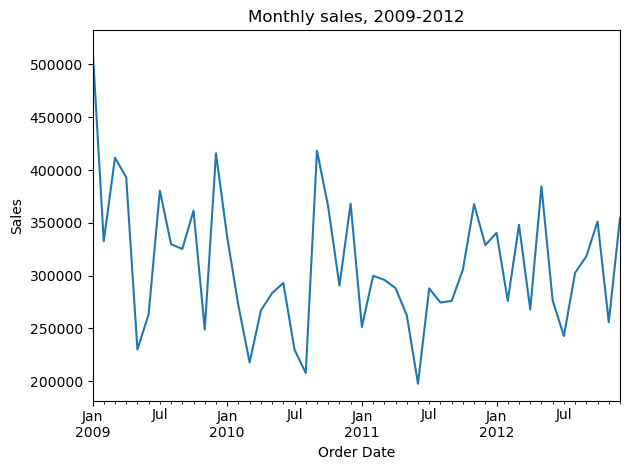

2009-01 516303
2011-06 197741


Order Date
1     1444923.0
2     1180084.0
3     1273681.0
4     1216483.0
5     1160896.0
6     1030859.0
7     1141104.0
8     1115015.0
9     1337957.0
10    1383714.0
11    1163393.0
12    1467490.0
Name: Sales, dtype: float64

In [12]:
monthly = df.groupby(df["Order Date"].dt.to_period("M"))["Sales"].sum()
monthly.plot(title="Monthly sales, 2009-2012")
plt.ylabel("Sales")
plt.tight_layout()
plt.savefig("outputs/monthly_sales.png")
plt.show()

print(monthly.idxmax(), round(monthly.max()))
print(monthly.idxmin(), round(monthly.min()))
display(df.groupby(df["Order Date"].dt.month)["Sales"].sum().round(0))

,sales,profit,margin_pct
Product Category,,,
Furniture,5178591.0,117433.0,2.3
Office Supplies,3752762.0,518021.0,13.8
Technology,5984248.0,886314.0,14.8


,Sales,Profit
Product Sub-Category,,
Tables,1896008.0,-99062.0
Bookcases,822652.0,-33582.0
"Scissors, Rulers and Trimmers",80996.0,-7799.0
Rubber Bands,15007.0,-103.0
Storage & Organization,1070183.0,6664.0


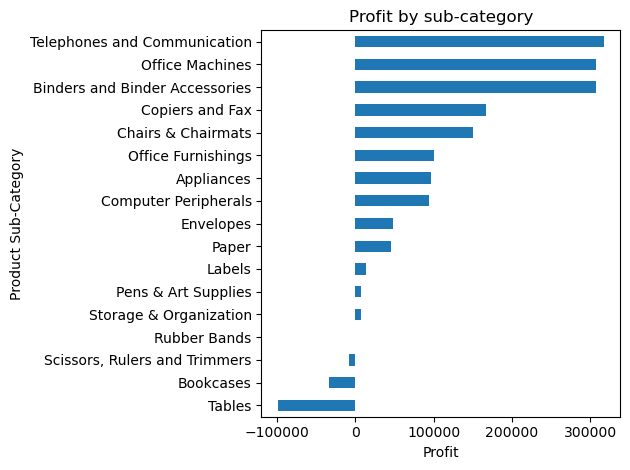

In [13]:
cat = df.groupby("Product Category").agg(
    sales=("Sales", "sum"),
    profit=("Profit", "sum"),
).round(0)
cat["margin_pct"] = (cat["profit"] / cat["sales"] * 100).round(1)
display(cat)

sub = df.groupby("Product Sub-Category")[["Sales", "Profit"]].sum().round(0).sort_values("Profit")
display(sub.head(5))

sub["Profit"].plot(kind="barh", title="Profit by sub-category")
plt.xlabel("Profit")
plt.tight_layout()
plt.savefig("outputs/profit_by_subcategory.png")
plt.show()

In [14]:
display(df.groupby("Ship Mode")["ship_days"].agg(["count", "mean", "min", "max"]).round(2))
display(df.nlargest(3, "ship_days")[["Order ID", "Order Date", "Ship Date", "ship_days", "Ship Mode"]])
print((df["ship_days"] > 7).sum())

,count,mean,min,max
Ship Mode,,,,
Delivery Truck,1146,2.04,0,17
Express Air,983,2.00,0,19
Regular Air,6270,2.04,0,92


,Order ID,Order Date,Ship Date,ship_days,Ship Mode
6582,353,2010-12-30,2011-04-01,92,Regular Air
1327,1699,2010-12-29,2011-03-23,84,Regular Air
3602,19841,2010-12-26,2011-01-26,31,Regular Air


108


In [15]:
losses = df[df["Profit"] < 0]
print(len(losses), round(len(losses) / len(df) * 100, 1))
print(round(losses["Profit"].sum()), round(df["Profit"].sum()))

4264 50.8
-1102503 1521768


(8399, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8399 entries, 0 to 8398
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Row ID                8399 non-null   int64  
 1   Order ID              8399 non-null   int64  
 2   Order Date            8399 non-null   object 
 3   Order Priority        8399 non-null   object 
 4   Order Quantity        8399 non-null   int64  
 5   Sales                 8399 non-null   float64
 6   Discount              8399 non-null   float64
 7   Ship Mode             8399 non-null   object 
 8   Profit                8399 non-null   float64
 9   Unit Price            8399 non-null   float64
 10  Shipping Cost         8399 non-null   float64
 11  Customer Name         8399 non-null   object 
 12  Province              8399 non-null   object 
 13  Region                8399 non-null   object 
 14  Customer Segment      8399 non-null   object 
 15  Product Ca

,Row ID,Order ID,Order Date,Order Priority,Order Quantity,Sales,Discount,Ship Mode,Profit,Unit Price,...,Customer Name,Province,Region,Customer Segment,Product Category,Product Sub-Category,Product Name,Product Container,Product Base Margin,Ship Date
0,1,3,10/13/2010,Low,6,261.54,0.04,Regular Air,-213.25,38.94,...,Muhammed MacIntyre,Nunavut,Nunavut,Small Business,Office Supplies,Storage & Organization,"Eldon Base for stackable storage shelf, platinum",Large Box,0.80,10/20/2010
1,49,293,10/1/2012,High,49,10123.02,0.07,Delivery Truck,457.81,208.16,...,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Appliances,"1.7 Cubic Foot Compact ""Cube"" Office Refrigera...",Jumbo Drum,0.58,10/2/2012
2,50,293,10/1/2012,High,27,244.57,0.01,Regular Air,46.71,8.69,...,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Binders and Binder Accessories,"Cardinal Slant-D® Ring Binder, Heavy Gauge Vinyl",Small Box,0.39,10/3/2012


Product Base Margin    63
dtype: int64

1/1/2009 9/9/2012
2009-01-01 00:00:00 2012-12-30 00:00:00
  Order Date  Ship Date  Year  ship_days
0 2010-10-13 2010-10-20  2010          7
1 2012-10-01 2012-10-02  2012          1
2 2012-10-01 2012-10-03  2012          2


,orders,sales,profit,margin_pct,sales_growth_pct
Year,,,,,
2009,1394,4209139.0,434539.0,10.3,NaN
2010,1393,3549681.0,363871.0,10.3,-15.7
2011,1317,3436817.0,381456.0,11.1,-3.2
2012,1392,3719964.0,341902.0,9.2,8.2


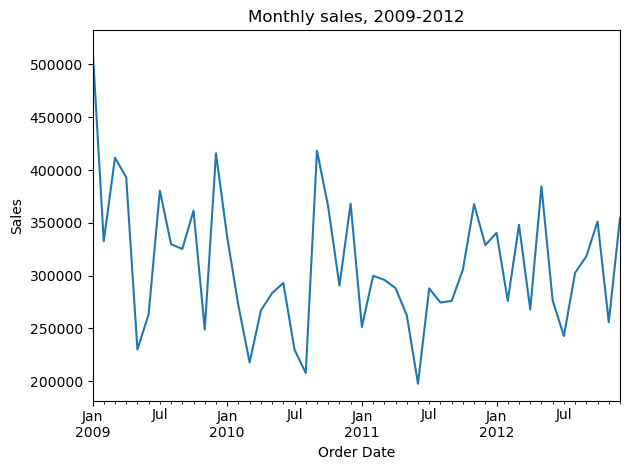

2009-01 516303
2011-06 197741


Order Date
1     1444923.0
2     1180084.0
3     1273681.0
4     1216483.0
5     1160896.0
6     1030859.0
7     1141104.0
8     1115015.0
9     1337957.0
10    1383714.0
11    1163393.0
12    1467490.0
Name: Sales, dtype: float64

,sales,profit,margin_pct
Product Category,,,
Furniture,5178591.0,117433.0,2.3
Office Supplies,3752762.0,518021.0,13.8
Technology,5984248.0,886314.0,14.8


,Sales,Profit
Product Sub-Category,,
Tables,1896008.0,-99062.0
Bookcases,822652.0,-33582.0
"Scissors, Rulers and Trimmers",80996.0,-7799.0
Rubber Bands,15007.0,-103.0
Storage & Organization,1070183.0,6664.0


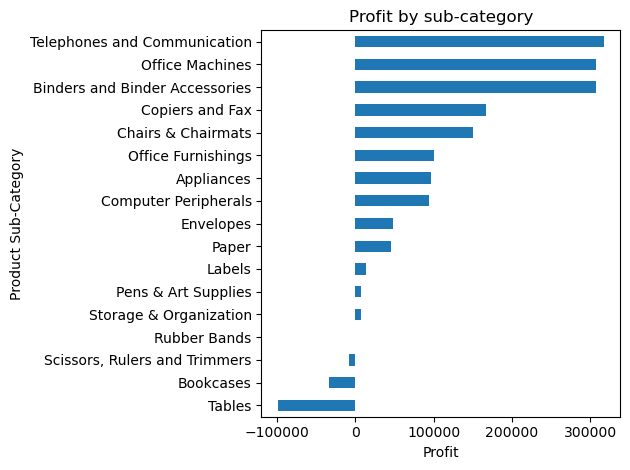

,count,mean,min,max
Ship Mode,,,,
Delivery Truck,1146,2.04,0,17
Express Air,983,2.00,0,19
Regular Air,6270,2.04,0,92


,Order ID,Order Date,Ship Date,ship_days,Ship Mode
6582,353,2010-12-30,2011-04-01,92,Regular Air
1327,1699,2010-12-29,2011-03-23,84,Regular Air
3602,19841,2010-12-26,2011-01-26,31,Regular Air


108
4264 50.8
-1102503 1521768


In [16]:
# ===================== CELL 1 | Q1: load the data =====================
import pandas as pd
# import = bring a library into this notebook so we can use its tools.
# pandas = the library that gives us DataFrames (tables) and nearly every tool used below.
# "as pd" = a nickname, so we type pd.something instead of pandas.something. Everyone uses pd.

import matplotlib.pyplot as plt
# matplotlib = the charting library. ".pyplot" = its drawing module (the part we use).
# "as plt" = the standard nickname. Pandas draws charts through it, and we use it to add labels and save.

df = pd.read_csv("data/superstore_sales.csv", encoding="mac_roman")
# df = the name we give the table (short for DataFrame). "=" attaches that name to whatever is on the right.
# pd.read_csv(...) = function from pandas: reads a CSV file and returns a DataFrame.
# "data/superstore_sales.csv" = the path: file inside the "data" folder next to this notebook.
#   the quotes make it text. Forward slashes work on Windows too.
# encoding="mac_roman" = keyword argument (name=value): which table converts the file's bytes into characters.
#   without it pandas assumes utf-8 and crashes: UnicodeDecodeError ... byte 0xa8.
#   encoding="latin1" would load WITHOUT error but turn the symbol ® into ¨. No error does not mean correct.
#   only text columns are affected, the numbers are identical either way.


# ===================== CELL 2 | Q1: first look =====================
print(df.shape)
# print() = show a value in the output.
# df.shape = ATTRIBUTE (stored info, no brackets): (number of rows, number of columns).
# use it first to confirm the file loaded with the size you expect.

df.info()
# info() = METHOD (an action, so it has brackets): prints every column's name, how many cells are filled,
#   and its type (dtype). int64 = whole numbers, float64 = decimals, str/object = text.
# check 1: "Order Date" shows as text, so it must be converted before any date maths.
# check 2: Order ID and Row ID are numbers but they are labels. Never sum or average an ID.

display(df.head(3))
# head(3) = the first 3 rows (the default is 5). It confirms what one row looks like.
# display() = Jupyter's way to show a table. Jupyter only auto-shows the LAST line of a cell,
#   so display() is how you show several things in one cell.

missing = df.isna().sum()
# df.isna() = a table of True/False the same shape as df: True wherever a cell is empty (NaN).
# .sum() = adds down each column. True counts as 1, so this gives the count of empty cells per column.
# "missing =" saves the result (a Series: column name -> count) so we can filter it on the next line.

display(missing[missing > 0])
# missing > 0 = True/False per column: "does this column have gaps?"
# missing[ ... ] = square brackets with True/False KEEP only the entries that are True.
# so we see only the columns with a problem, instead of scrolling past all 21.
# READ IT: the few gaps are in a column we do not use, so we leave them alone (cleaning is Level 2).


# ===================== CELL 3 | Q2: turn text into real dates =====================
print(df["Order Date"].min(), df["Order Date"].max())
# df["Order Date"] = pick ONE column by name (gives a Series). Square brackets + quoted name.
# .min() = smallest value in the column. .max() = largest value.
# print(a, b) = show two things on one line, separated by a space.
# THIS ANSWER IS WRONG ON PURPOSE: the column is still TEXT, and text sorts character by character,
#   so "9/9/2012" looks "bigger" than "12/30/2012" because "9" > "1". Text dates cannot be compared as dates.

df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
# df["Order Date"] =  on the LEFT: overwrite that column. Assigning to a name that already exists replaces it.
# pd.to_datetime(...) = pandas function that changes text into real datetime values.
# first argument df["Order Date"] = the column of text to convert.
# format="%m/%d/%Y" = keyword argument: describes how the text is laid out. The codes:
#     %m = month as a number (10)
#     %d = day of the month (13)
#     %Y = 4-digit year (2010)         (lowercase %y would be a 2-digit year: 10)
#     "/" = a literal slash: it must match the slashes in the text.
#   other codes you will meet: %B = month name (October), %H:%M:%S = hours:minutes:seconds.
# why month FIRST: the data has dates like 10/13/2010 and there is no month 13.
#   if we wrote "%d/%m/%Y" pandas would raise a ValueError on that value.
# without format= pandas guesses, and 10/1/2012 could be read as 10 January instead of 1 October.

df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")
# same conversion for the second date column: same layout in the text, so the same format.
# both date columns must be real dates before we can subtract one from the other below.

print(df["Order Date"].min(), df["Order Date"].max())
# the same line as before, but now it compares real dates, so min/max are truly the earliest and latest.
# READ IT: this is the period our findings cover. Always know the time span of your data.

df["Year"] = df["Order Date"].dt.year
# df["Year"] =  a name that does NOT exist yet creates a NEW column.
# .dt = "datetime accessor": unlocks date tools on a datetime column (like .str does for text).
# .year = pull out only the year, as a whole number. Others: .month, .quarter, .day_name().
# if the column were still text, .dt raises AttributeError: Can only use .dt accessor with datetimelike values.

df["ship_days"] = (df["Ship Date"] - df["Order Date"]).dt.days
# (A - B) = subtracting two datetime columns, row by row, gives a column of time gaps (a "timedelta").
# the brackets matter: they make the subtraction happen FIRST. Without them .dt.days would
#   attach only to df["Order Date"] and the line would fail.
# .dt.days = convert each time gap into a whole number of days.

print(df[["Order Date", "Ship Date", "Year", "ship_days"]].head(3))
# df[[ ... ]] = DOUBLE brackets. The inner [ ] is a list of column names, the outer [ ] does the selecting.
#   a list gives back a TABLE. A single name, df["Year"], gives back one column.
#   df["Order Date", "Year"] (one bracket) fails with KeyError.
# .head(3) = first 3 rows. print() shows them. A quick sanity check that the new columns look right.


# ===================== CELL 4 | Q3: year by year =====================
yearly = df.groupby("Year").agg(
    # yearly = a NEW table we are building. The name is our choice.
    # df.groupby("Year") = split the rows into one group per Year value (2009, 2010, ...).
    #   groupby alone shows nothing. It needs an action after it, and here the action is .agg(...)
    # .agg(...) = "aggregate": apply summaries to each group.
    #   we use .agg here because we want SEVERAL different summaries, each with its own column name.
    orders=("Order ID", "nunique"),  # new_column_name=("source column", "summary to apply").
    # nunique = number of DISTINCT values. One order has several lines (rows), so "count" would count lines.
    #   nunique counts each Order ID once, which gives the real number of orders.
    sales=("Sales", "sum"),          # sum = add up every Sales value inside each year's group.
    profit=("Profit", "sum"),        # same idea for Profit.
).round(0)
# .round(0) = round every number in the result to 0 decimals (whole dollars).
# done AFTER summing: rounding is for display, never round before you calculate.

yearly["margin_pct"] = (yearly["profit"] / yearly["sales"] * 100).round(1)
# I use yearly[...] here, not df[...], because the profit and sales TOTALS live in the yearly table I just defined.
#   df has one row per order line. yearly has one row per year.
# yearly["margin_pct"] =  a new name, so a new column is added to yearly.
# margin % is ALWAYS: profit / sales * 100  (cents of profit kept per dollar of sales).
# we divide TOTAL profit by TOTAL sales (a "ratio of sums"), so big sales count more than small ones.
#   averaging each line's own margin would treat a $5 line the same as a $50,000 line.
# * 100 turns the fraction (0.10) into a percent (10). .round(1) keeps one decimal.

yearly["sales_growth_pct"] = (yearly["sales"].pct_change() * 100).round(1)
# .pct_change() = compare each row with the row ABOVE it: (this - previous) / previous.
# the result is a fraction (0.08 = 8%), so * 100 turns it into a percent.
# the first row is NaN: it has no row above it. That is expected, not an error.
# it needs the rows in time order. groupby already sorted the years ascending.
# related tools (extrapolations):
#   .diff() = (this - previous) in raw units, so dollars instead of a percent.
#   .pct_change(periods=12) = compare with 12 rows back, e.g. the same month last year in monthly data.

display(yearly)
# display() shows the finished table.
# READ IT: put sales_growth_pct next to profit and margin_pct. If sales go UP while profit goes DOWN,
#   the business is selling more but keeping less of each dollar. That is the story in this table.


# ===================== CELL 5 | Q4: monthly trend and seasons =====================
monthly = df.groupby(df["Order Date"].dt.to_period("M"))["Sales"].sum()
# monthly = a Series (one column of numbers with labels): total sales per calendar month.
# df.groupby( X ): X is usually a column NAME. Here X is a computed column the same length as df.
# df["Order Date"].dt.to_period("M") = turn each date into its month ("2010-10"), dropping the day,
#   so every day of a month falls into the same group. "M" = month, "Q" = quarter, "Y" = year.
# ["Sales"] = after grouping, pick the column to summarise.
# .sum() = add it up inside each group.
# why NO .agg here: only ONE column and ONE summary are wanted, so the short form is enough.
#   rule of thumb:  .agg(name=(col, func))  -> several summaries, or custom column names.
#                   ["col"].sum() / .mean() -> one summary of one column.

monthly.plot(title="Monthly sales, 2009-2012")
# .plot() on a Series = draw a chart: the index (the months) goes on the x axis, the values on y.
# the default kind is a line, which suits time. title= sets the heading text.

plt.ylabel("Sales")
# plt.ylabel(...) = label for the vertical axis. A chart without labelled axes is unfinished.

plt.tight_layout()
# adjusts the spacing so labels are not cut off at the edges.

plt.savefig("outputs/monthly_sales.png")
# save the chart as an image file in the "outputs" folder. It must come BEFORE plt.show().
# if the "outputs" folder does not exist you get FileNotFoundError.

plt.show()
# draw the chart in the notebook now.

print(monthly.idxmax(), round(monthly.max()))
# monthly.max() = the largest VALUE. monthly.idxmax() = the LABEL (the month) where that value sits.
# round(x) = Python's own function (not a pandas method): rounds to a whole number.

print(monthly.idxmin(), round(monthly.min()))
# idxmin / min = the weakest month and its value. Same logic, opposite end.

display(df.groupby(df["Order Date"].dt.month)["Sales"].sum().round(0))
# same pattern, but .dt.month = the month NUMBER 1-12 with the year ignored, so all Januaries pool together.
#   to_period("M") -> 48 groups = a timeline.     .dt.month -> 12 groups = seasonality.
# READ IT: months that are high in this list are high EVERY year. That is a seasonal peak.
#   with only four years of data, call it a pattern, not a law.


# ===================== CELL 6 | Q5: categories that make or lose money =====================
cat = df.groupby("Product Category").agg(
    sales=("Sales", "sum"),      # total sales for each category
    profit=("Profit", "sum"),    # total profit for each category
).round(0)
# cat = a summary table with one row per category. Same recipe as yearly: only the grouping column changed.
# .agg is used because we want two different columns summarised and named in one go.

cat["margin_pct"] = (cat["profit"] / cat["sales"] * 100).round(1)
# I use cat[...] because the totals live in the cat table I just defined.
# margin % = profit / sales * 100: the same formula every time, on totals.

display(cat)
# READ IT: a category with high sales but a very low margin is a lot of work for little profit.

sub = df.groupby("Product Sub-Category")[["Sales", "Profit"]].sum().round(0).sort_values("Profit")
# NO .agg here: every selected column gets the SAME summary (sum), so the shortcut is enough.
# [["Sales", "Profit"]] = double brackets after groupby: pick SEVERAL columns (a list inside the brackets).
#   one bracket, ["Profit"], would give a single column; double brackets give a table.
# .sum() = add up both selected columns inside each sub-category.
# .round(0) = whole dollars.
# .sort_values("Profit") = order the rows by the Profit column. Ascending is the DEFAULT, so lowest first.
#   add ascending=False to put the biggest first instead.

display(sub.head(5))
# head(5) = the first 5 rows. Because of the ascending sort above, these are the 5 LOWEST-profit sub-categories.
# sub.tail(5) would show the 5 best.
# READ IT: negative profit means that sub-category loses money overall, despite its sales.

sub["Profit"].plot(kind="barh", title="Profit by sub-category")
# sub["Profit"] = one column (a Series). Its index, the sub-category names, becomes the y-axis labels.
# kind="barh" = horizontal bars (h for horizontal). Better than vertical bars when names are long.

plt.xlabel("Profit")
# for barh the values run along the x axis, so we label x here (it was ylabel for the vertical chart).

plt.tight_layout()
# keeps the long labels from being cut off.

plt.savefig("outputs/profit_by_subcategory.png")
# save the picture into the outputs folder (before show).

plt.show()
# draw it in the notebook.


# ===================== CELL 7 | Q6: shipping speed =====================
display(df.groupby("Ship Mode")["ship_days"].agg(["count", "mean", "min", "max"]).round(2))
# df.groupby("Ship Mode") = one group per shipping method.
# ["ship_days"] = the column to summarise.
# .agg([ ... ]) = here .agg takes a LIST of function names: several summaries of the SAME column,
#   one output column per name. (In Cell 4, .agg took name=(column, function) because the columns differed.)
# count = how many rows, mean = average, min / max = the extremes.
# .round(2) = 2 decimals.
# READ IT: if the fastest-sounding mode has the same average as the cheapest, suspect the DATA before
#   you believe the result. Real express shipping should be faster.

display(df.nlargest(3, "ship_days")[["Order ID", "Order Date", "Ship Date", "ship_days", "Ship Mode"]])
# df.nlargest(3, "ship_days") = the 3 rows with the biggest ship_days.
#   same result as df.sort_values("ship_days", ascending=False).head(3), in one step.
#   df.nsmallest(...) gives the other end.
# [[ ... ]] after it = show only these columns, so the result fits the screen.
# READ IT: extreme values are not automatically errors. Look at the dates (orders near year-end shipping
#   in the new year) before deciding to remove anything.

print((df["ship_days"] > 7).sum())
# df["ship_days"] > 7 = True/False for each row: "took more than a week?"
# the outer brackets make .sum() act on that whole True/False column.
# .sum() on True/False counts the Trues (True = 1, False = 0). So this = how many lines took more than a week.


# ===================== CELL 8 | Q7: lines that lose money =====================
losses = df[df["Profit"] < 0]
# df["Profit"] < 0 = True/False for each row (True = this line lost money).
# df[ ... ] with True/False inside = keep only the True rows.
# losses = a smaller table that holds only the loss-making lines.

print(len(losses), round(len(losses) / len(df) * 100, 1))
# len(table) = number of rows in it.
# len(losses) / len(df) = the fraction of all rows that lost money. * 100 turns it into a percent.
# round(x, 1) = Python's round, to 1 decimal. Two values separated by a comma print on one line.

print(round(losses["Profit"].sum()), round(df["Profit"].sum()))
# first value = the total lost on loss-making lines (a negative number).
# second value = the total profit across ALL lines (the net result).
# READ IT: the gap between them shows how much of the winners' profit is eaten by the losers.


# ===================== CELL 9 | the answers, in plain English =====================
# Q1 Size and loading: 21 columns; needs encoding="mac_roman"; only one unused column has gaps.
# Q2 Dates: after conversion, real dates covering the full four years 2009-2012.
# Q3 Years: compare sales_growth_pct against profit and margin_pct. Sales can recover while profit falls.
# Q4 Seasons: the pooled month totals show which months peak every year, and which is the weakest.
# Q5 Categories: sales size and profit are different questions. A big category can have a tiny margin,
#    and sub-categories with negative profit lose money overall.
# Q6 Shipping: typical time is days not weeks, and the "fast" mode is not faster: question the data.
# Q7 Losses: a large share of lines lose money, and their total cancels part of the winners' profit.
# LIMIT: this shows WHAT happened, not WHY. Whether discounts cause the losses needs more digging.